In [28]:
# PROJECT: Predicting Insomnia Using Classification Models

# Predicting Insomnia Using Classification Models
# Goal: Predict whether a participant belongs to the moderate/severe insomnia group.

# - `Insomnia = 1`: Moderate or severe insomnia according to the dataset's doctor-opinion label
# - `Insomnia = 0`: Other insomnia categories
# - Models: KNN, Naive Bayes, Decision Tree, and SVM

# Step 1: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ## Step 2: Load the dataset and inspect it

df = pd.read_excel("Onidra_Raw_Dataset.xlsx")

print(df.head())
print("Dataset shape:", df.shape)
df.info()
print("\nMissing values in each column:")
print(df.isnull().sum())

# ## Step 3: Select and clean the columns

# Keep only the columns used in this project.
# The question-code columns are left out because their meanings have not been confirmed/ it leads to messy dataset.

columns_needed = [
    'Participant ID', 'Gender', 'Age', 'LivingStatus', 'Occupation',
    'EducationalYear', 'MaritalStatus', 'SmokingHabit', 'Alcohol',
    'Place_of_ Education', 'UniversityType', 'SleepTime',
    'Asthma', 'Hypertension', 'HeartDisease', 'CardiovascularDisease',
    'Cancer', 'Diabetes', 'Doctor Opinion Insomnia', 'Doctor Opinion Anxiety'
]

df = df[columns_needed]
df = df.rename(columns={
    'Place_of_ Education': 'PlaceOfEducation',
    'Doctor Opinion Insomnia': 'InsomniaOpinion',
    'Doctor Opinion Anxiety': 'AnxietyOpinion'
})

# Remove extra spaces and make text lowercase so labels are consistent.
text_columns = df.select_dtypes(include='object').columns 
#select_dtypes(include='object') → text-type columns select karta hai., .columns → un columns ke names deta hai.
for column in text_columns:
    df[column] = df[column].str.strip().str.lower()

# A participant ID should be unique. Keep the first row if an ID is repeated.
print("Duplicate participant IDs:", df['Participant ID'].duplicated().sum())
df = df.drop_duplicates(subset='Participant ID') #Code first occurrence ko rakhega aur doosri occurrence remove kar dega.

# We cannot create the target when the insomnia opinion is missing.
df = df.dropna(subset=['InsomniaOpinion']) #coz our whole conclusion is based on onsomnia opinion only.

# Fill missing predictor values with the most common value in that column.
for column in df.columns:
    if column not in ['Participant ID', 'InsomniaOpinion']:
        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].mode()[0]) # 0 so that it will select the highest value of mode

print("\nMissing values after cleaning:")
print(df.isnull().sum())


# Check the labels in the data before mapping them to numbers.
for column in df.columns:
    if column != 'Participant ID':
        print(column, ":", df[column].unique()) # unique() checks that in every cloumn what unique values are present

# ## Step 4: Create the target and additional features

# Target: 1 = moderate/severe insomnia; 0 = all other insomnia categories.
df['Insomnia'] = df['InsomniaOpinion'].isin(
    ['moderate_insomnia', 'severe_insomnia']
).astype(int)

# Count how many of the listed chronic diseases are marked "yes".
disease_columns = [
    'Asthma', 'Hypertension', 'HeartDisease',
    'CardiovascularDisease', 'Cancer', 'Diabetes'
]
df['DiseaseCount'] = (df[disease_columns] == 'yes').sum(axis=1)
# Har participant ko listed diseases mein se kitni diseases hain, unka count nikalna.

# 1 means the participant's sleep time is after midnight.
df['LateSleeper'] = df['SleepTime'].isin(['12 to 1', 'after 1']).astype(int)

# Count yes answers for smoking and alcohol.
df['RiskyHabits'] = (
    (df['SmokingHabit'] == 'yes').astype(int)+
    (df['Alcohol'] == 'yes').astype(int))


# Remove the ID and original target label from the input data.
df = df.drop(columns=['Participant ID', 'InsomniaOpinion'])

print(df[['Insomnia', 'DiseaseCount', 'LateSleeper', 'RiskyHabits']].head())
print("\nTarget counts:")
print(df['Insomnia'].value_counts())


  Participant ID  Gender    Age    LivingStatus  Occupation EducationalYear  \
0        P000001  Female  24-28     with family     student         1st/2nd   
1        P000002    Male  18-23  without family     student        graduate   
2        P000003    Male    >28  without family  job holder        graduate   
3        P000004    Male  18-23  without family  unemployed        graduate   
4        P000005  Female    >28     with family     student        graduate   

  MaritalStatus SmokingHabit Alcohol Place_of_ Education  ...  \
0       Married           no      no               urban  ...   
1     Unmarried           no      no               urban  ...   
2     Unmarried          yes      no               urban  ...   
3     Unmarried          yes      no               rural  ...   
4     Unmarried           no      no               rural  ...   

                     AD6                     AD7 AD8 AD9 AD10 AD11 AD12  \
0             Depression  Yes, related to health   4   3   

C:\Users\asus\AppData\Local\Temp\ipykernel_12468\3400708181.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include='object').columns


Duplicate participant IDs: 0

Missing values after cleaning:
Participant ID           0
Gender                   0
Age                      0
LivingStatus             0
Occupation               0
EducationalYear          0
MaritalStatus            0
SmokingHabit             0
Alcohol                  0
PlaceOfEducation         0
UniversityType           0
SleepTime                0
Asthma                   0
Hypertension             0
HeartDisease             0
CardiovascularDisease    0
Cancer                   0
Diabetes                 0
InsomniaOpinion          0
AnxietyOpinion           0
dtype: int64
Gender : <StringArray>
['female', 'male', 'third']
Length: 3, dtype: str
Age : <StringArray>
['24-28', '18-23', '>28', '<18']
Length: 4, dtype: str
LivingStatus : <StringArray>
['with family', 'without family']
Length: 2, dtype: str
Occupation : <StringArray>
['student', 'job holder', 'unemployed']
Length: 3, dtype: str
EducationalYear : <StringArray>
['1st/2nd', 'graduate', '3rd/4th

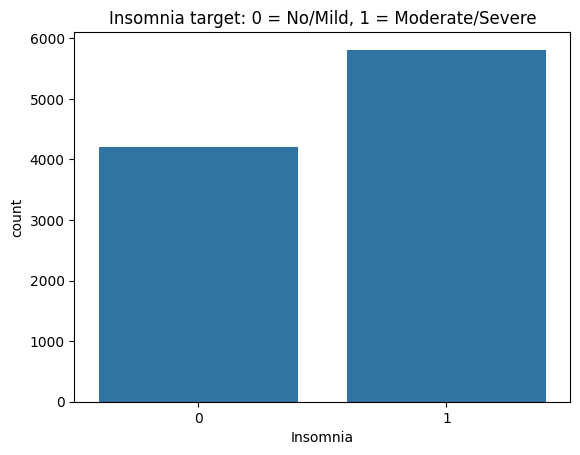

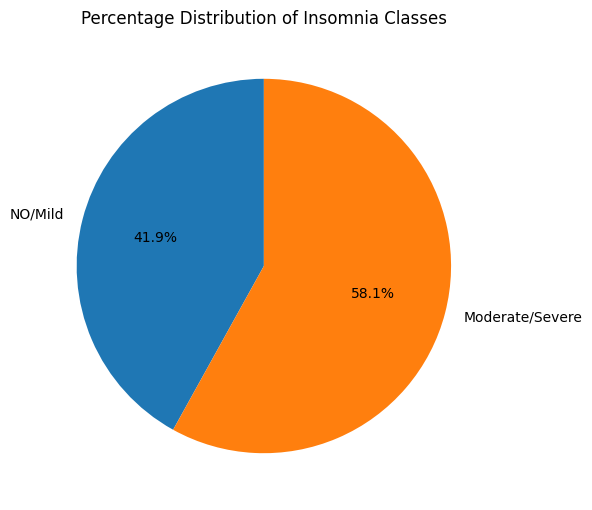

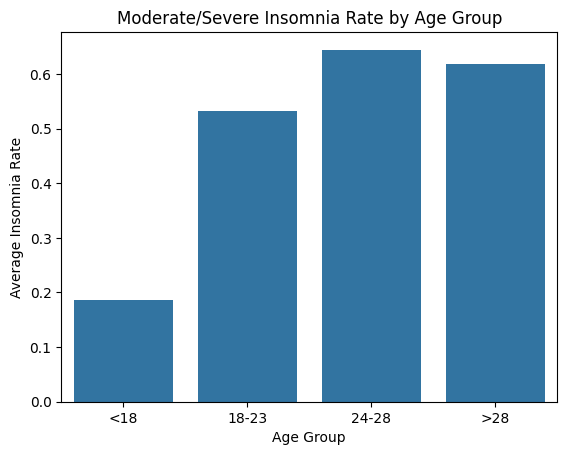

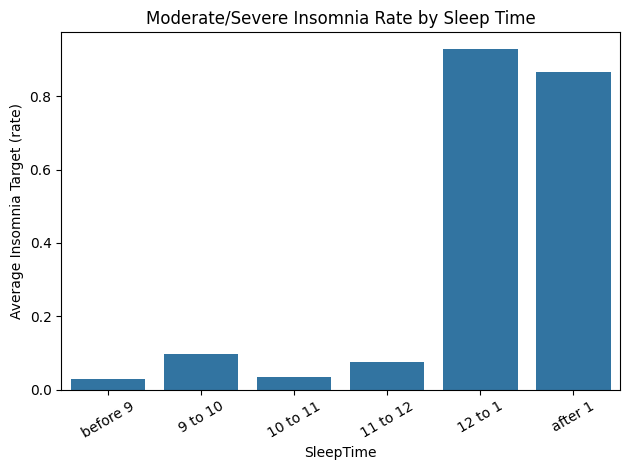

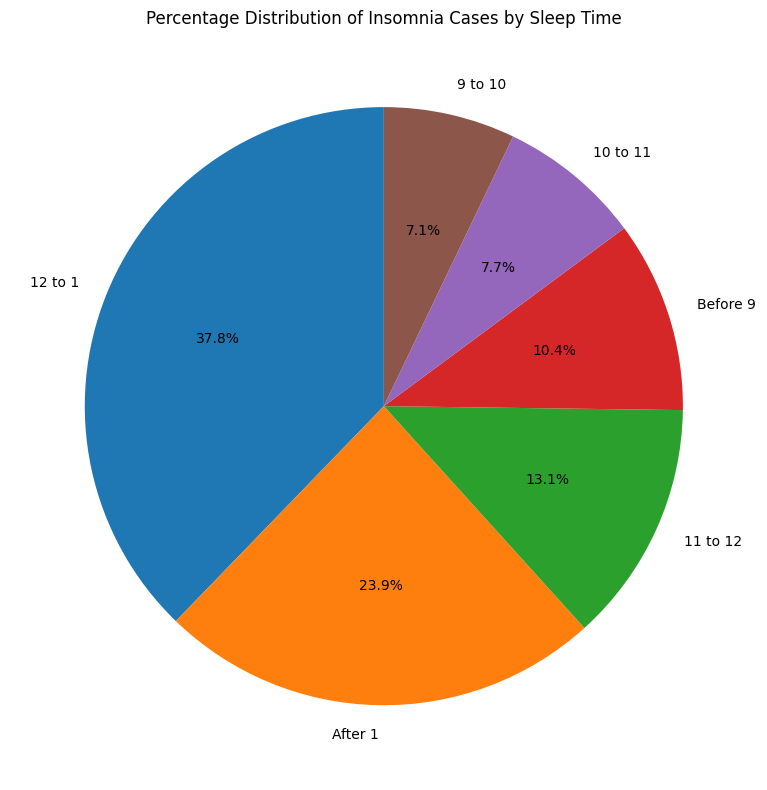

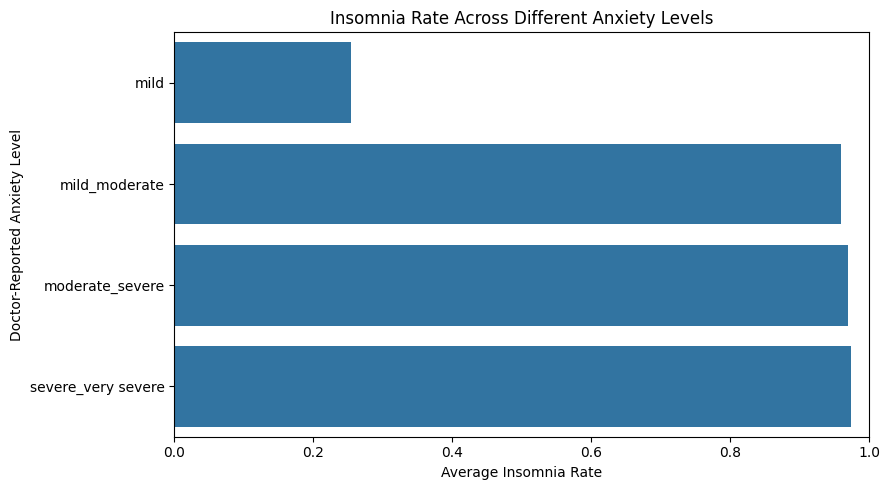

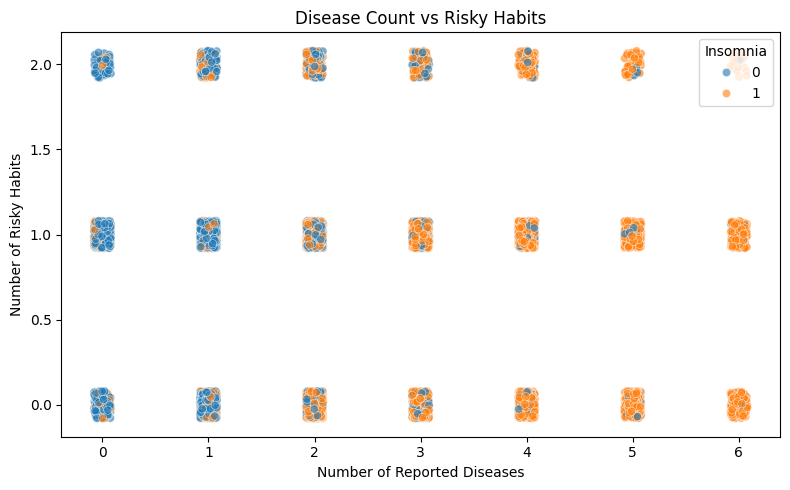

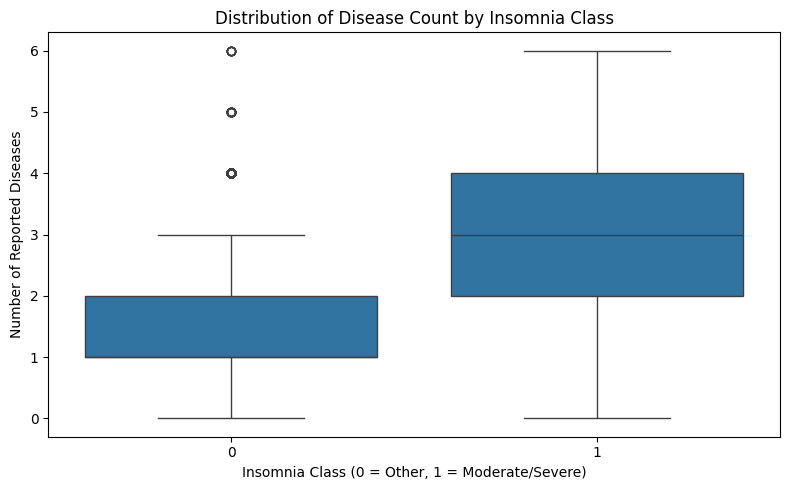

In [29]:
# ## Step 5: Explore the data with simple charts

# Chart 1: Number of participants in each target group.
sns.countplot(data=df, x='Insomnia')
plt.title('Insomnia target: 0 = No/Subthreshold, 1 = Moderate/Severe')
plt.show()

# 1.1 PIE CHART: Percentage of each insomnia class
insomnia_counts = df['Insomnia'].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.pie(
    insomnia_counts,
    labels=insomnia_counts.index.map({
        0: 'NO/Mild',
        1: 'Moderate/Severe'
    }),
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Percentage Distribution of Insomnia Classes')
plt.tight_layout()
plt.show()

# Chart 2: Average insomnia rate by age group
sns.barplot(
    data=df,
    x='Age',
    y='Insomnia',
    order=['<18', '18-23', '24-28', '>28'],
    errorbar=None
)

plt.title('Moderate/Severe Insomnia Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Insomnia Rate')
plt.show()

# Chart 3: Average target rate by sleep time.
sleep_order = ['before 9', '9 to 10', '10 to 11', '11 to 12', '12 to 1', 'after 1']
sns.barplot(data=df, x='SleepTime', y='Insomnia', order=sleep_order,errorbar=None)
plt.title('Moderate/Severe Insomnia Rate by Sleep Time')
plt.xticks(rotation=30)
plt.ylabel('Average Insomnia Target (rate)')
plt.tight_layout()
plt.show()

# Chart 3.1: Pie chart of participants by sleep time

sleep_labels = {
    'before 9': 'Before 9',
    '9 to 10': '9 to 10',
    '10 to 11': '10 to 11',
    '11 to 12': '11 to 12',
    '12 to 1': '12 to 1',
    'after 1': 'After 1',
    0: 'Before 9',
    1: '9 to 10',
    2: '10 to 11',
    3: '11 to 12',
    4: '12 to 1',
    5: 'After 1'
}

sleep_counts = df['SleepTime'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    sleep_counts,
    labels=[sleep_labels.get(i, str(i)) for i in sleep_counts.index],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Participants by Sleep Time')
plt.tight_layout()
plt.show()


# Chart 4: Moderate/Severe Insomnia Rate by Anxiety Opinion

anxiety_order = [
    'mild',
    'mild_moderate',
    'moderate_severe',
    'severe_very severe'
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    y='AnxietyOpinion',
    x='Insomnia',
    order=anxiety_order,
    errorbar=None,
    orient='h'
)

plt.title('Insomnia Rate Across Different Anxiety Levels')
plt.xlabel('Average Insomnia Rate')
plt.ylabel('Doctor-Reported Anxiety Level')
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


# 5. SCATTER PLOT: Disease count vs risky habits
# Small jitter helps separate overlapping observations.
plot_df = df.copy()

np.random.seed(42)
plot_df['DiseaseCount_Jitter'] = (
    plot_df['DiseaseCount'] +
    np.random.uniform(-0.08, 0.08, len(plot_df))
)

plot_df['RiskyHabits_Jitter'] = (
    plot_df['RiskyHabits'] +
    np.random.uniform(-0.08, 0.08, len(plot_df))
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df,
    x='DiseaseCount_Jitter',
    y='RiskyHabits_Jitter',
    hue='Insomnia',
    alpha=0.6
)
plt.title('Disease Count vs Risky Habits')
plt.xlabel('Number of Reported Diseases')
plt.ylabel('Number of Risky Habits')
plt.tight_layout()
plt.show()

# Chart 6: Distribution of Reported Diseases by Insomnia Class

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Insomnia',
    y='DiseaseCount'
)

plt.title('Distribution of Disease Count by Insomnia Class')
plt.xlabel('Insomnia Class (0 = Other, 1 = Moderate/Severe)')
plt.ylabel('Number of Reported Diseases')

plt.tight_layout()
plt.show()


Data after encoding:
   Age  EducationalYear  SmokingHabit  Alcohol  SleepTime  Asthma  \
0    2                0             0        0          5       0   
1    1                2             0        0          3       0   
2    3                2             1        0          0       0   
3    1                2             1        0          2       0   
4    3                2             0        0          2       1   

   Hypertension  HeartDisease  CardiovascularDisease  Cancer  ...  \
0             1             1                      1       1  ...   
1             1             0                      0       0  ...   
2             0             0                      0       0  ...   
3             0             0                      0       0  ...   
4             0             0                      0       0  ...   

   LateSleeper  RiskyHabits  Gender_male  Gender_third  \
0            1            0            0             0   
1            0            0      

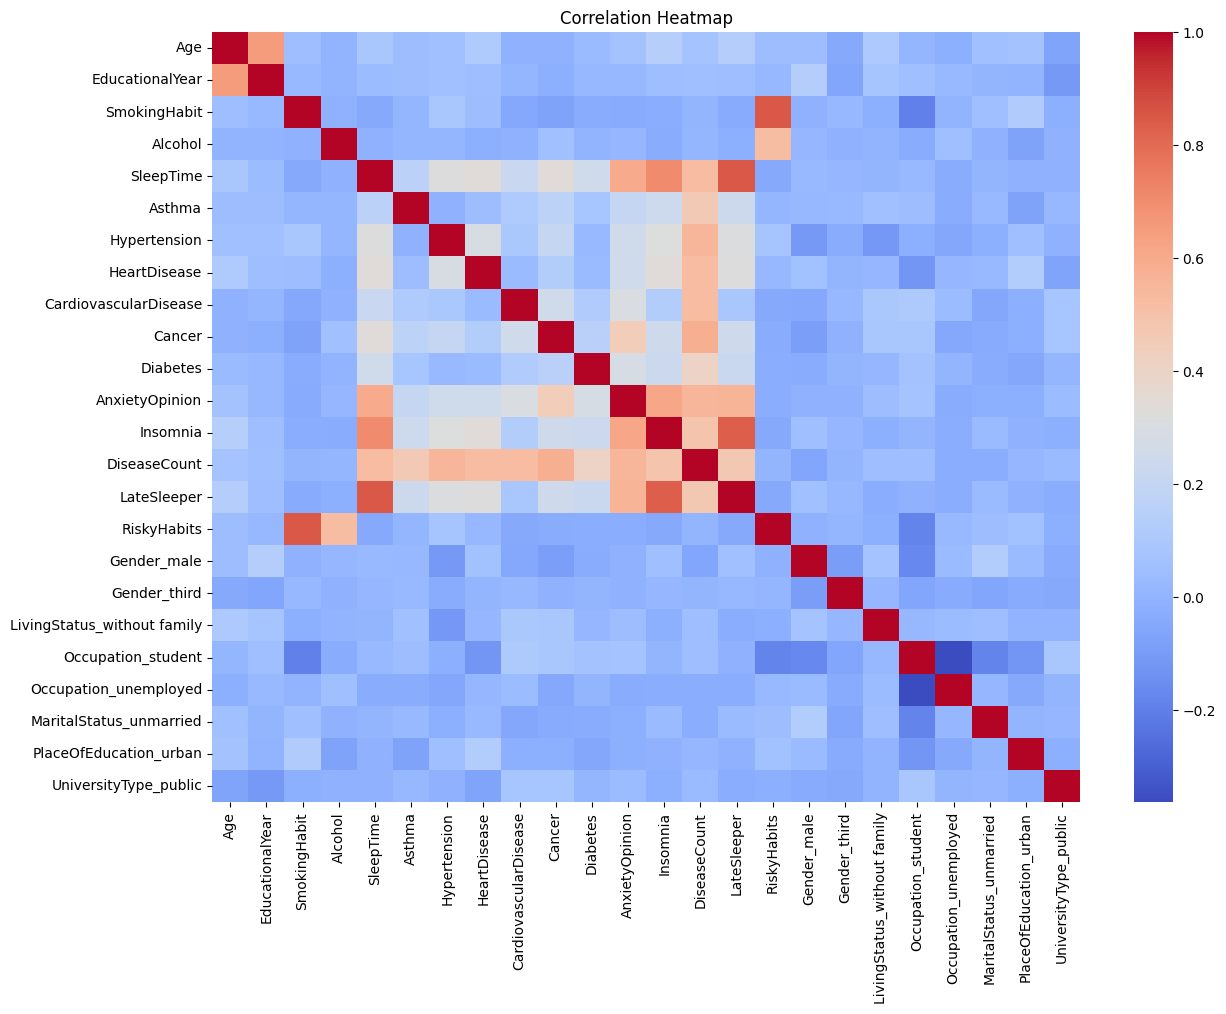

Correlation with Insomnia target:
Insomnia                       1.000000
LateSleeper                    0.833564
SleepTime                      0.702608
AnxietyOpinion                 0.614112
DiseaseCount                   0.492472
HeartDisease                   0.338712
Hypertension                   0.316733
Cancer                         0.248660
Asthma                         0.241333
Diabetes                       0.230028
Age                            0.140648
CardiovascularDisease          0.127181
Gender_male                    0.047585
EducationalYear                0.044252
MaritalStatus_unmarried        0.028553
Gender_third                   0.013022
Occupation_student             0.001700
PlaceOfEducation_urban        -0.014347
UniversityType_public         -0.019581
LivingStatus_without family   -0.024951
SmokingHabit                  -0.030480
Occupation_unemployed         -0.031969
Alcohol                       -0.033129
RiskyHabits                   -0.043596
Name: 

In [30]:
# Step 6: Convert text categories into numbers

# Convert ordered categories to numbers in their natural order.
df['Age'] = df['Age'].map({'<18': 0, '18-23': 1, '24-28': 2, '>28': 3})
df['SleepTime'] = df['SleepTime'].map({
    'before 9': 0, '9 to 10': 1, '10 to 11': 2,
    '11 to 12': 3, '12 to 1': 4, 'after 1': 5
})
df['EducationalYear'] = df['EducationalYear'].map({
    '1st/2nd': 0, '3rd/4th/5th': 1, 'graduate': 2
})
df['AnxietyOpinion'] = df['AnxietyOpinion'].map({
    'mild': 0, 'mild_moderate': 1,
    'moderate_severe': 2, 'severe_very severe': 3
})

# Convert yes/no answers into 1/0.
yes_no_columns = ['SmokingHabit', 'Alcohol'] + disease_columns
for column in yes_no_columns:
    df[column] = df[column].map({'no': 0, 'yes': 1})

# Fill any values that did not match the mappings with the most common value.
for column in df.columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

# One-hot encode categories that do not have a natural order.
category_columns = [
    'Gender', 'LivingStatus', 'Occupation', 'MaritalStatus',
    'PlaceOfEducation', 'UniversityType'
]
df = pd.get_dummies(df, columns=category_columns, drop_first=True, dtype=int)

print("Data after encoding:")
print(df.head())
print("Shape after encoding:", df.shape)

# ## Step 7: View a correlation heatmap

plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

print("Correlation with Insomnia target:")
print(df.corr()['Insomnia'].sort_values(ascending=False))

In [31]:
# Step 8: Split data into training and testing sets

# X contains the input features. y contains the answer we want to predict.
X = df.drop('Insomnia', axis=1)
y = df['Insomnia']

# Use 70% of the data for training and 30% for testing.
# stratify keeps the class proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# KNN and SVM work better when features are on a similar scale.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 7005
Testing rows: 3003


KNN Accuracy: 93.64 %
KNN Precision: 0.95
KNN Recall: 0.94
KNN F1 Score: 0.945

KNN Confusion Matrix:
[[1173   87]
 [ 104 1639]]

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92      1260
           1       0.95      0.94      0.94      1743

    accuracy                           0.94      3003
   macro avg       0.93      0.94      0.93      3003
weighted avg       0.94      0.94      0.94      3003



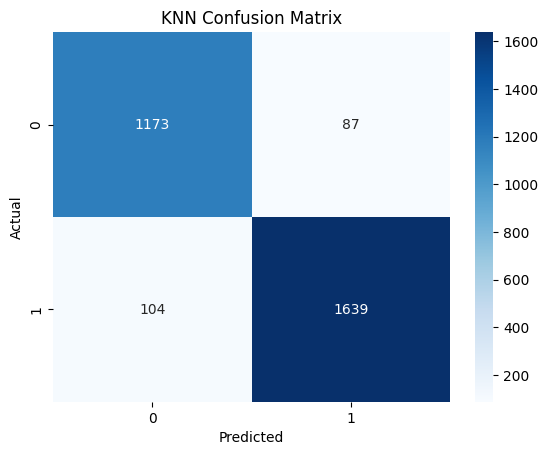

In [32]:
# Step 9: Model 1 — K-Nearest Neighbours (KNN)

# Create the KNN model. It looks at the 5 nearest training examples.
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model using scaled training data.
knn.fit(X_train_scaled, y_train)

# Predict the target for the test data.
knn_pred = knn.predict(X_test_scaled)

# Evaluate KNN.
knn_accuracy = accuracy_score(y_test, knn_pred) * 100
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)

print("KNN Accuracy:", round(knn_accuracy, 2), "%")
print("KNN Precision:", round(knn_precision, 3))
print("KNN Recall:", round(knn_recall, 3))
print("KNN F1 Score:", round(knn_f1, 3))
print("\nKNN Confusion Matrix:")
print(confusion_matrix(y_test, knn_pred))
print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Naive Bayes Accuracy: 92.14 %
Naive Bayes Precision: 0.917
Naive Bayes Recall: 0.951
Naive Bayes F1 Score: 0.934

Naive Bayes Confusion Matrix:
[[1110  150]
 [  86 1657]]

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.88      0.90      1260
           1       0.92      0.95      0.93      1743

    accuracy                           0.92      3003
   macro avg       0.92      0.92      0.92      3003
weighted avg       0.92      0.92      0.92      3003



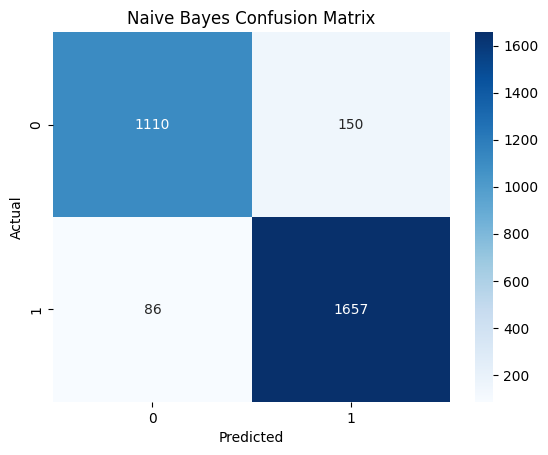

In [33]:
# Step 10: Model 2 — Naive Bayes

# Create the Gaussian Naive Bayes model.
naive_bayes = GaussianNB()

# Train Naive Bayes using the encoded training data.
naive_bayes.fit(X_train, y_train)

# Predict the target for the test data.
nb_pred = naive_bayes.predict(X_test)

# Evaluate Naive Bayes.
nb_accuracy = accuracy_score(y_test, nb_pred) * 100
nb_precision = precision_score(y_test, nb_pred, zero_division=0)
nb_recall = recall_score(y_test, nb_pred, zero_division=0)
nb_f1 = f1_score(y_test, nb_pred, zero_division=0)

print("Naive Bayes Accuracy:", round(nb_accuracy, 2), "%")
print("Naive Bayes Precision:", round(nb_precision, 3))
print("Naive Bayes Recall:", round(nb_recall, 3))
print("Naive Bayes F1 Score:", round(nb_f1, 3))
print("\nNaive Bayes Confusion Matrix:")
print(confusion_matrix(y_test, nb_pred))
print("\nNaive Bayes Classification Report:")
print(classification_report(y_test, nb_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, nb_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Decision Tree Accuracy: 94.97 %
Decision Tree Precision: 0.948
Decision Tree Recall: 0.967
Decision Tree F1 Score: 0.957

Decision Tree Confusion Matrix:
[[1167   93]
 [  58 1685]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      1260
           1       0.95      0.97      0.96      1743

    accuracy                           0.95      3003
   macro avg       0.95      0.95      0.95      3003
weighted avg       0.95      0.95      0.95      3003



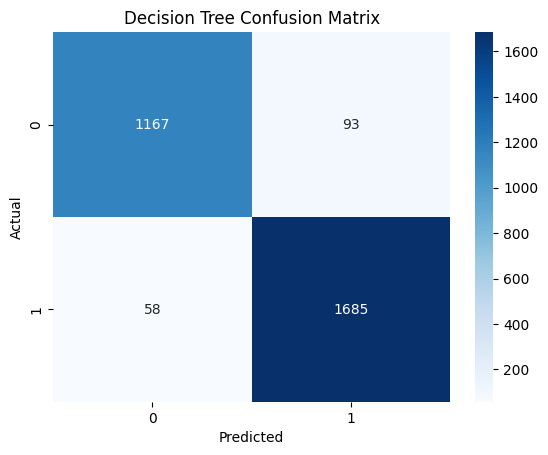

In [34]:
# Step 11: Model 3 — Decision Tree

# Limit the tree depth to 5 so the model is easier to understand.
decision_tree = DecisionTreeClassifier(max_depth=5, random_state=42)

# Train the Decision Tree using the encoded training data.
decision_tree.fit(X_train, y_train)

# Predict the target for the test data.
tree_pred = decision_tree.predict(X_test)

# Evaluate Decision Tree.
tree_accuracy = accuracy_score(y_test, tree_pred) * 100
tree_precision = precision_score(y_test, tree_pred, zero_division=0)
tree_recall = recall_score(y_test, tree_pred, zero_division=0)
tree_f1 = f1_score(y_test, tree_pred, zero_division=0)

print("Decision Tree Accuracy:", round(tree_accuracy, 2), "%")
print("Decision Tree Precision:", round(tree_precision, 3))
print("Decision Tree Recall:", round(tree_recall, 3))
print("Decision Tree F1 Score:", round(tree_f1, 3))
print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, tree_pred))
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, tree_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, tree_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

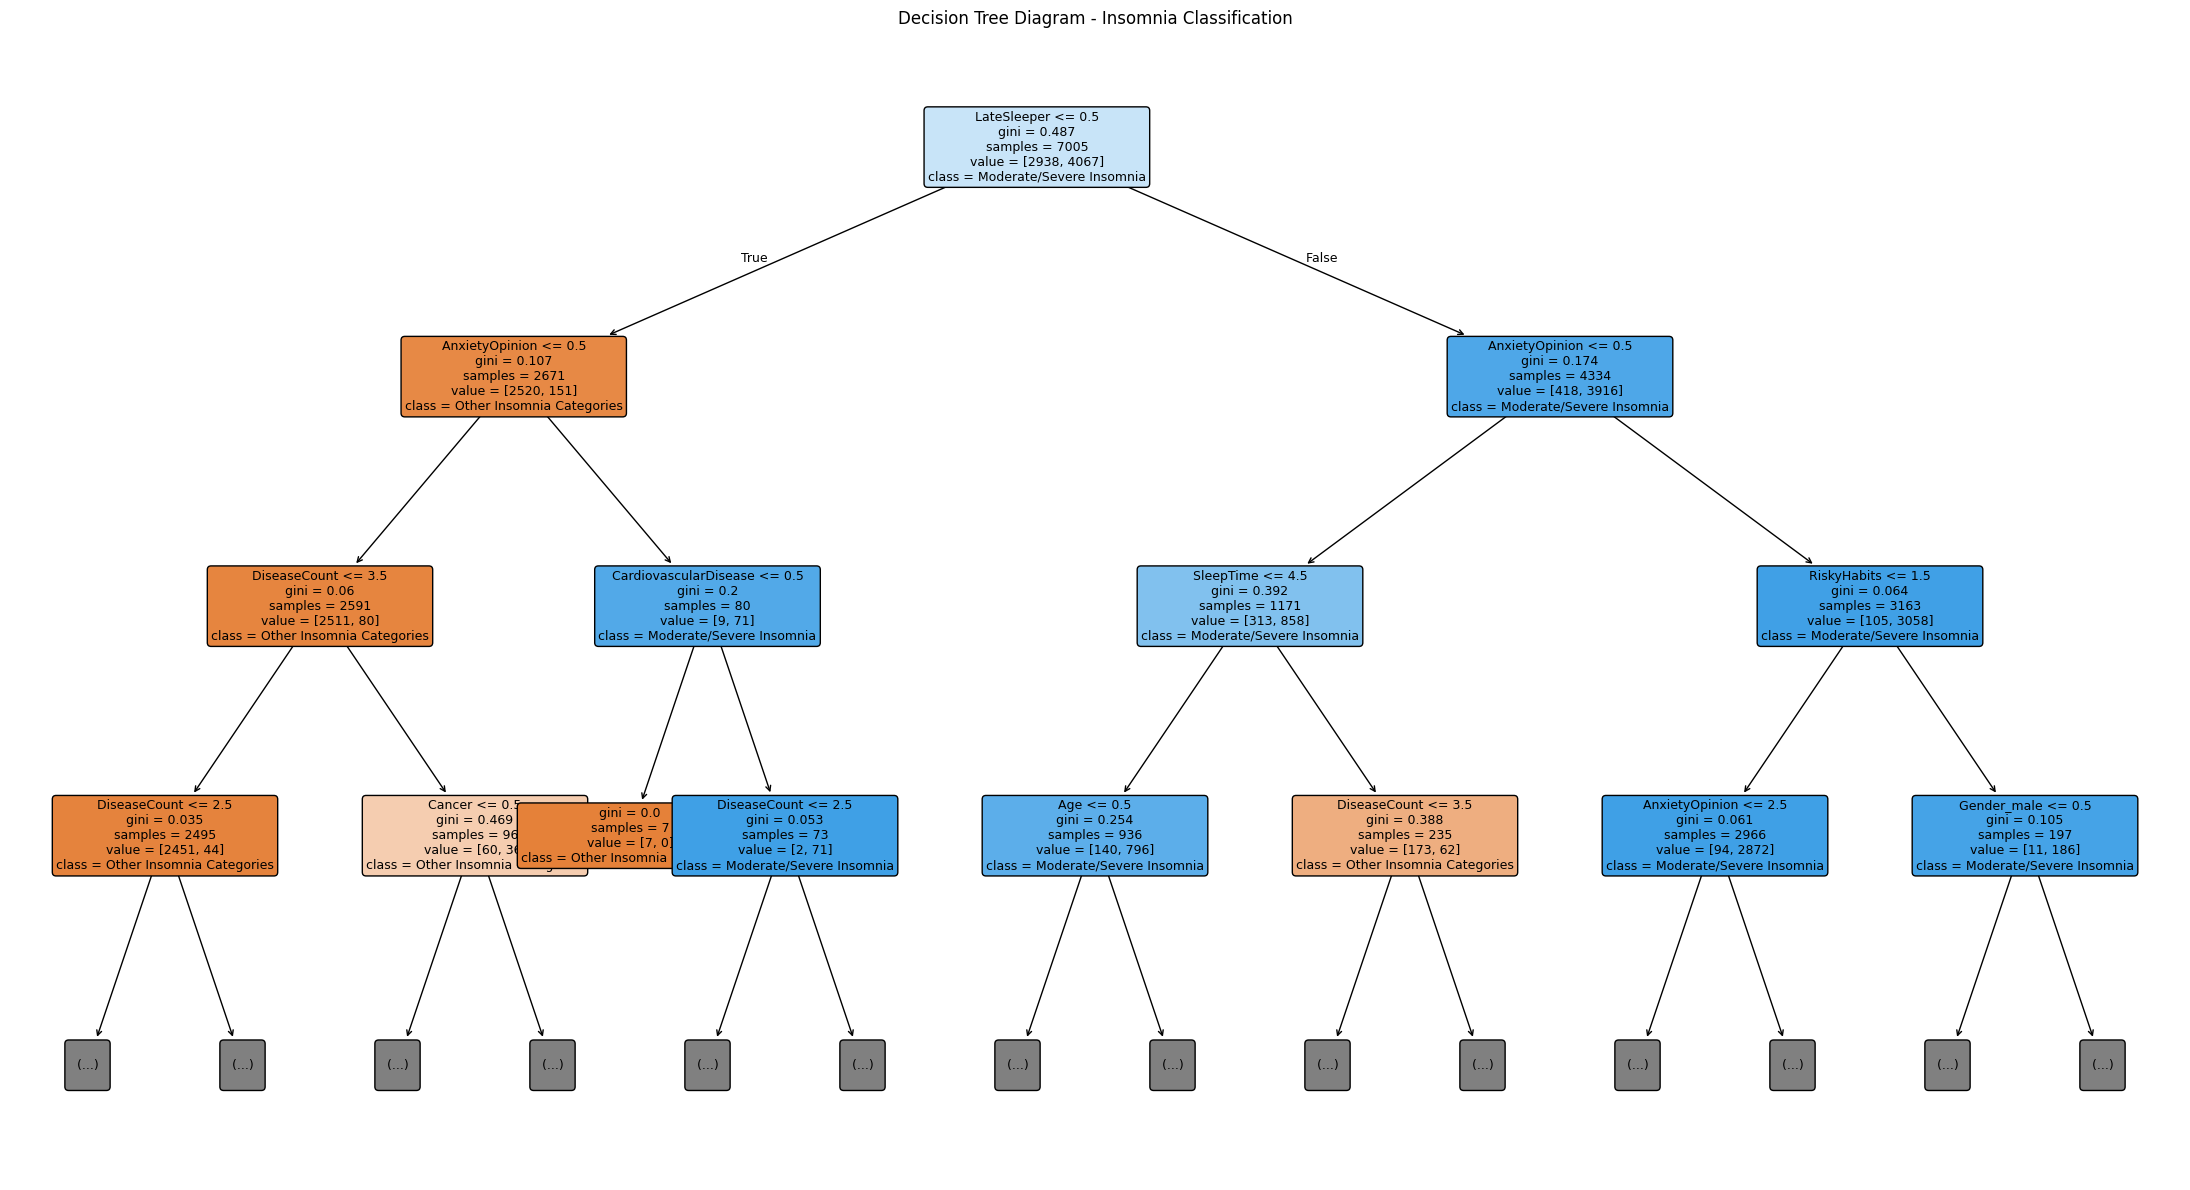

In [35]:

# DECISION TREE DIAGRAM

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 12))

plot_tree(
    decision_tree,
    filled=True,
    feature_names=X.columns,
    class_names=['Other Insomnia Categories',
                 'Moderate/Severe Insomnia'],
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Diagram - Insomnia Classification")
plt.tight_layout()
plt.show()


Top 10 Decision Tree features:
       Feature  Importance
   LateSleeper    0.839716
AnxietyOpinion    0.073573
     SleepTime    0.045778
  DiseaseCount    0.022269
        Cancer    0.004724


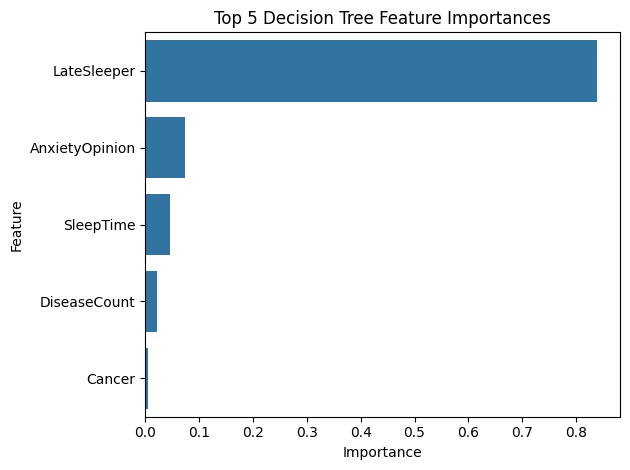

In [36]:
# Step 14: Decision Tree feature importance and conclusion

# Feature importance shows which inputs the Decision Tree used most.
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': decision_tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print("Top 5 Decision Tree features:")
print(feature_importance.head(5).to_string(index=False))

sns.barplot(data=feature_importance.head(5), x='Importance', y='Feature')
plt.title('Top 5 Decision Tree Feature Importances')
plt.tight_layout()
plt.show()

SVM Accuracy: 94.11 %
SVM Precision: 0.932
SVM Recall: 0.969
SVM F1 Score: 0.95

SVM Confusion Matrix:
[[1137  123]
 [  54 1689]]

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.93      1260
           1       0.93      0.97      0.95      1743

    accuracy                           0.94      3003
   macro avg       0.94      0.94      0.94      3003
weighted avg       0.94      0.94      0.94      3003



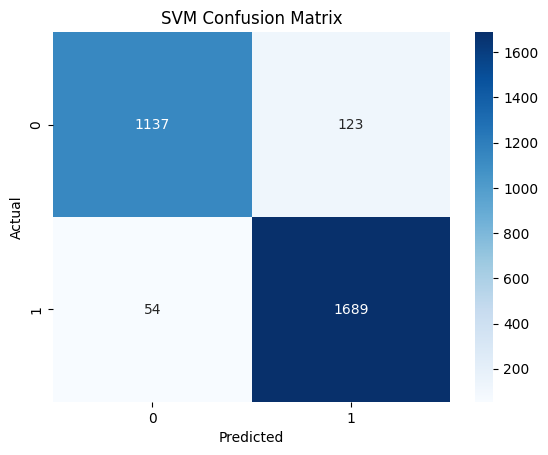

In [37]:
# Step 12: Model 4 — Support Vector Machine (SVM)

# Create the SVM model.
svm_model = SVC(random_state=42)

# Train SVM using scaled training data.
svm_model.fit(X_train_scaled, y_train)

# Predict the target for the test data.
svm_pred = svm_model.predict(X_test_scaled)

# Evaluate SVM.
svm_accuracy = accuracy_score(y_test, svm_pred) * 100
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)

print("SVM Accuracy:", round(svm_accuracy, 2), "%")
print("SVM Precision:", round(svm_precision, 3))
print("SVM Recall:", round(svm_recall, 3))
print("SVM F1 Score:", round(svm_f1, 3))
print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))
print("\nSVM Classification Report:")
print(classification_report(y_test, svm_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Blues')
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

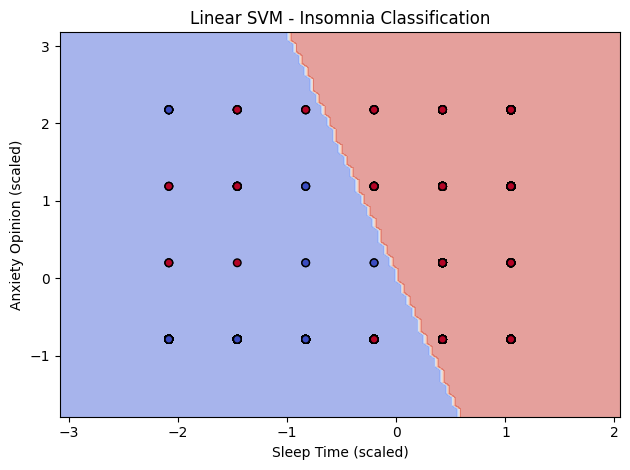

In [46]:
# To visualise how a Support Vector Machine (SVM) classifier separates participants into two classes—moderate/severe 
# insomnia and other insomnia categories—based on their age and sleep time using a linear decision boundary.


# SVM DIAGRAM

# Select two features: SleepTime and AnxietyOpinion
X_train_2d = X_train_scaled[:, [
    X.columns.get_loc('SleepTime'),
    X.columns.get_loc('AnxietyOpinion')
]]

svm_lin = SVC(kernel="linear")
svm_lin.fit(X_train_2d, y_train)

DecisionBoundaryDisplay.from_estimator(
    svm_lin,
    X_train_2d,
    response_method="predict",
    cmap="coolwarm",
    alpha=0.5,
    xlabel="Sleep Time (scaled)",
    ylabel="Anxiety Opinion (scaled)"
)

plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="k",
    s=30
)

plt.title("Linear SVM - Insomnia Classification")
plt.tight_layout()
plt.show()

COMPARISON OF FOUR CLASSIFICATION MODELS
        Model  Accuracy (%)  Precision  Recall  F1 Score
          KNN        93.640      0.950   0.940     0.945
  Naive Bayes        92.141      0.917   0.951     0.934
Decision Tree        94.972      0.948   0.967     0.957
          SVM        94.106      0.932   0.969     0.950


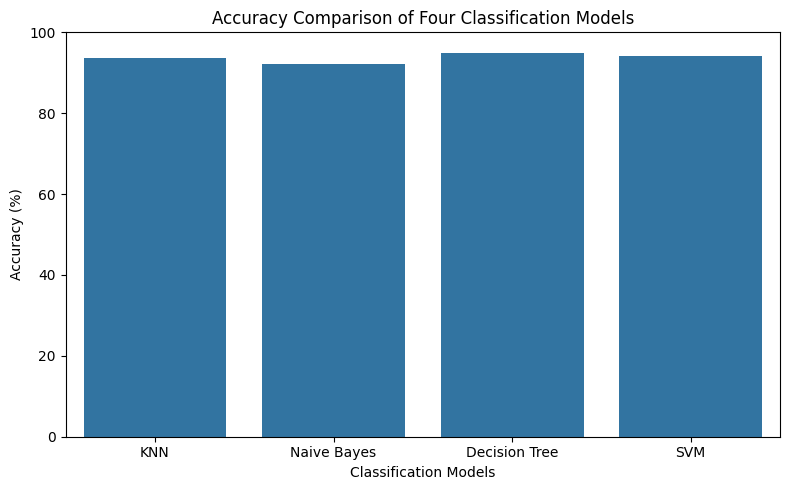


FINAL MODEL RANKING
        Model  Total Points
Decision Tree          14.0
          SVM          12.0
          KNN           9.0
  Naive Bayes           5.0

OVERALL BEST PERFORMING MODEL: Decision Tree
Test Accuracy: 94.972 %
Total Points: 14.0

PROJECT CONCLUSION
The four classification models were trained and evaluated separately.
Their performance was compared using Accuracy, Precision, Recall and F1 Score.
A ranking and points method was also used to compare the overall performance of all four models.
Based on the total points, Decision Tree performed best among the four classification models.
Accuracy alone does not tell the whole story, so Precision, Recall and F1 Score should also be considered.
These results classify the dataset's labels and should not be treated as a medical diagnosis.


In [39]:
# Final Comparison of All Four Classification Models

# Compare all four classification models using evaluation metrics.
comparison = pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes', 'Decision Tree', 'SVM'],
    'Accuracy (%)': [knn_accuracy, nb_accuracy, tree_accuracy, svm_accuracy],
    'Precision': [knn_precision, nb_precision, tree_precision, svm_precision],
    'Recall': [knn_recall, nb_recall, tree_recall, svm_recall],
    'F1 Score': [knn_f1, nb_f1, tree_f1, svm_f1]
})

comparison = comparison.round(3)

print("COMPARISON OF FOUR CLASSIFICATION MODELS")
print(comparison.to_string(index=False))

# Compare model accuracy using a bar chart.
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x='Model', y='Accuracy (%)')
plt.title('Accuracy Comparison of Four Classification Models')
plt.ylim(0, 100)
plt.ylabel('Accuracy (%)')
plt.xlabel('Classification Models')
plt.tight_layout()
plt.show()

# Give points to models based on their performance in each metric.
scores = pd.DataFrame()

scores['Accuracy'] = comparison['Accuracy (%)'].rank(
    ascending=False, method='min'
)

scores['Precision'] = comparison['Precision'].rank(
    ascending=False, method='min'
)

scores['Recall'] = comparison['Recall'].rank(
    ascending=False, method='min'
)

scores['F1 Score'] = comparison['F1 Score'].rank(
    ascending=False, method='min'
)


# Convert ranks into points.
points = 5 - scores

comparison['Total Points'] = points.sum(axis=1)


# Display final ranking and total points.
print("\nFINAL MODEL RANKING")

print(
    comparison[['Model', 'Total Points']]
    .sort_values(by='Total Points', ascending=False)
    .to_string(index=False)
)


# Select the overall best-performing model.
best_index = comparison['Total Points'].idxmax()

best_model_name = comparison.loc[best_index, 'Model']

best_accuracy = comparison.loc[best_index, 'Accuracy (%)']

print("\nOVERALL BEST PERFORMING MODEL:", best_model_name)
print("Test Accuracy:", best_accuracy, "%")
print("Total Points:", comparison.loc[best_index, 'Total Points'])


# PROJECT CONCLUSION
print("\nPROJECT CONCLUSION")

print("The four classification models were trained and evaluated separately.")

print("Their performance was compared using Accuracy, Precision, Recall and F1 Score.")

print("A ranking and points method was also used to compare the overall performance of all four models.")

print("Based on the total points,", best_model_name,
      "performed best among the four classification models.")

print("Accuracy alone does not tell the whole story, so Precision, Recall and F1 Score should also be considered.")

print("These results classify the dataset's labels and should not be treated as a medical diagnosis.")